# Práctica 2 — Media-varianza y modelos multifactoriales

## Quant Portfolio Management

Esta práctica estudia dos bloques complementarios:

1. **Optimización media-varianza**
   - estimación de retornos esperados y matriz de covarianzas;
   - cartera de mínima varianza;
   - cartera de máximo Sharpe;
   - frontera eficiente;
   - restricciones realistas de peso máximo y turnover;
   - comparación con Equal Weight y SPY;
   - validación out-of-sample.

2. **Modelos multifactoriales**
   - CAPM;
   - Fama-French 3 factores;
   - Carhart 4 factores;
   - Fama-French 5 factores;
   - análisis de alpha, betas, t-statistics y R² ajustado;
   - evolución temporal de exposiciones mediante rolling betas de 36 meses.

El objetivo no es únicamente encontrar una cartera óptima *in-sample*, sino analizar hasta qué punto sus resultados sobreviven fuera de muestra y cuánto de su comportamiento puede explicarse mediante exposiciones factoriales.

In [325]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from quantmgmt.data import load_prices
from quantmgmt.data.factors import load_fama_french_factors

from quantmgmt.risk import to_returns

from quantmgmt.optimizers.mean_variance import (
    estimate_inputs,
    min_variance,
    max_sharpe,
    efficient_frontier,
    target_volatility,
    portfolio_return,
    portfolio_volatility,
)

from quantmgmt.analytics.capm import (
    estimate_sector_betas,
    estimate_sml,
)

from quantmgmt.analytics.factors import (
    run_factor_regression,
    rolling_factor_betas,
)

In [326]:
SECTOR_TICKERS = [
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLI",
    "XLY",
    "XLP",
    "XLU",
    "XLB",
    "XLRE",
]

MARKET_TICKER = "SPY"

ALL_TICKERS = (
    SECTOR_TICKERS
    + [MARKET_TICKER]
)

START_DATE = "2010-01-01"
PERIODS_PER_YEAR = 12

In [327]:
prices = load_prices(
    tickers=ALL_TICKERS,
    start=START_DATE,
    interval="1mo",
)

prices.tail()

,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,
2026-06-01,744.920227,50.597153,52.796177,53.420937,184.733505,190.297928,82.527237,43.662479,45.009052,158.055099,117.022263
2026-07-01,745.179626,50.198986,59.198124,56.739189,179.357956,175.145615,84.494301,44.693798,44.026276,161.930267,115.834877
2026-08-01,765.149963,52.448631,63.582066,57.506474,174.660583,186.282608,84.424759,43.741814,41.921753,169.889801,116.333778
2026-09-01,762.630005,48.700001,61.500000,53.400002,166.979996,195.750000,80.599998,40.910000,39.439999,168.419998,108.839996
2026-10-01,769.049988,51.230000,67.970001,55.720001,166.800003,185.440002,87.750000,42.380001,41.880001,179.820007,115.500000


In [328]:
availability = pd.DataFrame(
    {
        "first_price": {
            ticker: prices[ticker].first_valid_index()
            for ticker in prices.columns
        },
        "last_price": {
            ticker: prices[ticker].last_valid_index()
            for ticker in prices.columns
        },
        "missing_prices": prices.isna().sum(),
    }
)

availability

,first_price,last_price,missing_prices
SPY,2010-01-01,2026-10-01,0
XLB,2010-01-01,2026-10-01,0
XLE,2010-01-01,2026-10-01,0
XLF,2010-01-01,2026-10-01,0
XLI,2010-01-01,2026-10-01,0
XLK,2010-01-01,2026-10-01,0
XLP,2010-01-01,2026-10-01,0
XLRE,2015-10-01,2026-10-01,69
XLU,2010-01-01,2026-10-01,0
XLV,2010-01-01,2026-10-01,0


### Disponibilidad histórica de XLRE

El ETF inmobiliario `XLRE` tiene una historia significativamente más corta que el resto del universo: sus datos comienzan en 2015.

No se imputan retornos anteriores a su existencia, ya que esto introduciría información artificial.

Por tanto, se adoptan dos criterios:

- Para los análisis que requieren los **10 sectores simultáneamente**, se utiliza la muestra común disponible desde 2015.
- Para la validación **out-of-sample 2010–2017**, se excluye `XLRE`, conservando los otros nueve sectores para evitar reducir el periodo de entrenamiento a apenas dos años.

Esta decisión preserva la información histórica disponible y evita cualquier imputación no justificable económicamente.

In [329]:
returns = to_returns(
    prices,
    method="simple",
    dropna=False,
)

returns.tail()

,SPY,XLB,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,
2026-06-01,-0.010293,-0.002540,-0.049689,0.042997,0.072522,-0.001428,0.008882,0.009680,0.027229,0.066165,-0.027768
2026-07-01,0.000348,-0.007869,0.121258,0.062115,-0.029099,-0.079624,0.023835,0.023620,-0.021835,0.024518,-0.010147
2026-08-01,0.026799,0.044815,0.074055,0.013523,-0.026190,0.063587,-0.000823,-0.021300,-0.047802,0.049154,0.004307
2026-09-01,-0.003293,-0.071472,-0.032746,-0.071409,-0.043974,0.050823,-0.045304,-0.064739,-0.059200,-0.008652,-0.064416
2026-10-01,0.008418,0.051951,0.105203,0.043446,-0.001078,-0.052669,0.088710,0.035933,0.061866,0.067688,0.061191


In [330]:
returns_summary = pd.DataFrame(
    {
        "first_return": {
            ticker: returns[ticker].first_valid_index()
            for ticker in returns.columns
        },
        "n_observations": returns.notna().sum(),
        "missing_returns": returns.isna().sum(),
    }
)

returns_summary

,first_return,n_observations,missing_returns
SPY,2010-02-01,201,1
XLB,2010-02-01,201,1
XLE,2010-02-01,201,1
XLF,2010-02-01,201,1
XLI,2010-02-01,201,1
XLK,2010-02-01,201,1
XLP,2010-02-01,201,1
XLRE,2015-11-01,132,70
XLU,2010-02-01,201,1
XLV,2010-02-01,201,1


In [331]:
sector_returns_common = (
    returns[SECTOR_TICKERS]
    .dropna()
)

print(
    "Periodo común:",
    sector_returns_common.index.min(),
    "->",
    sector_returns_common.index.max(),
)

print(
    "Observaciones:",
    len(sector_returns_common),
)

sector_returns_common.head()

Periodo común: 2015-11-01 00:00:00 -> 2026-10-01 00:00:00
Observaciones: 132


,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE
Date,,,,,,,,,,
2015-11-01,0.007102,0.019934,-0.000147,-0.003224,0.008660,-0.002347,-0.009222,-0.021257,0.009938,-0.006462
2015-12-01,-0.020811,-0.023644,-0.105170,0.017229,-0.025724,-0.028431,0.029176,0.021192,-0.043401,0.025327
2016-01-01,-0.037124,-0.088544,-0.034980,-0.077190,-0.056970,-0.051817,0.005348,0.049446,-0.107093,-0.063943
2016-02-01,-0.006547,-0.029006,-0.028002,-0.003611,0.042609,0.004453,0.003152,0.019375,0.078153,0.004796
2016-03-01,0.088217,0.071592,0.101659,0.027075,0.069735,0.066974,0.047383,0.079765,0.075731,0.106971


## 2. Estimación de inputs de Markowitz

La optimización media-varianza requiere dos inputs fundamentales:

- el vector de rentabilidades esperadas;
- la matriz de covarianzas entre activos.

En esta práctica se utilizan estimadores muestrales sobre retornos mensuales y se anualizan mediante:

- rentabilidad esperada anual = media mensual × 12;
- covarianza anual = covarianza mensual × 12.

Para mantener consistencia entre activos, esta sección utiliza la muestra común de los 10 ETFs sectoriales.

In [332]:
expected_returns, covariance_matrix = estimate_inputs(
    sector_returns_common,
    periods_per_year=PERIODS_PER_YEAR,
)

expected_returns

XLK     0.227849
XLF     0.132690
XLE     0.145887
XLV     0.111315
XLI     0.137052
XLY     0.125707
XLP     0.086649
XLU     0.102874
XLB     0.111885
XLRE    0.077533
dtype: float64

In [333]:
annual_volatility = pd.Series(
    np.sqrt(np.diag(covariance_matrix)),
    index=covariance_matrix.index,
    name="annual_volatility",
)

inputs_table = pd.DataFrame(
    {
        "Expected return %": expected_returns * 100,
        "Volatility %": annual_volatility * 100,
    }
)

inputs_table = inputs_table.sort_values(
    "Expected return %",
    ascending=False,
)

inputs_table.round(3)

,Expected return %,Volatility %
XLK,22.785,20.545
XLE,14.589,29.369
XLI,13.705,18.460
XLF,13.269,19.144
XLY,12.571,19.803
XLB,11.188,18.619
XLV,11.132,14.375
XLU,10.287,15.346
XLP,8.665,13.003
XLRE,7.753,16.981


In [334]:
covariance_matrix.round(4)

,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE
XLK,0.0422,0.0199,0.0150,0.0129,0.0242,0.0310,0.0095,0.0082,0.0203,0.0186
XLF,0.0199,0.0366,0.0367,0.0163,0.0292,0.0257,0.0127,0.0093,0.0275,0.0197
XLE,0.0150,0.0367,0.0863,0.0175,0.0311,0.0244,0.0153,0.0098,0.0332,0.0186
XLV,0.0129,0.0163,0.0175,0.0207,0.0169,0.0151,0.0120,0.0092,0.0186,0.0155
XLI,0.0242,0.0292,0.0311,0.0169,0.0341,0.0274,0.0156,0.0137,0.0295,0.0218
XLY,0.0310,0.0257,0.0244,0.0151,0.0274,0.0392,0.0122,0.0108,0.0266,0.0231
XLP,0.0095,0.0127,0.0153,0.0120,0.0156,0.0122,0.0169,0.0131,0.0159,0.0159
XLU,0.0082,0.0093,0.0098,0.0092,0.0137,0.0108,0.0131,0.0236,0.0139,0.0176
XLB,0.0203,0.0275,0.0332,0.0186,0.0295,0.0266,0.0159,0.0139,0.0347,0.0228
XLRE,0.0186,0.0197,0.0186,0.0155,0.0218,0.0231,0.0159,0.0176,0.0228,0.0288


In [335]:
correlation_matrix = (
    sector_returns_common.corr()
)

correlation_matrix.round(3)

,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE
XLK,1.000,0.506,0.248,0.438,0.639,0.762,0.357,0.260,0.531,0.532
XLF,0.506,1.000,0.652,0.591,0.825,0.677,0.510,0.316,0.771,0.608
XLE,0.248,0.652,1.000,0.414,0.573,0.419,0.400,0.217,0.606,0.373
XLV,0.438,0.591,0.414,1.000,0.638,0.530,0.643,0.415,0.696,0.635
XLI,0.639,0.825,0.573,0.638,1.000,0.750,0.649,0.484,0.859,0.697
XLY,0.762,0.677,0.419,0.530,0.750,1.000,0.473,0.355,0.721,0.688
XLP,0.357,0.510,0.400,0.643,0.649,0.473,1.000,0.656,0.658,0.719
XLU,0.260,0.316,0.217,0.415,0.484,0.355,0.656,1.000,0.485,0.675
XLB,0.531,0.771,0.606,0.696,0.859,0.721,0.658,0.485,1.000,0.722
XLRE,0.532,0.608,0.373,0.635,0.697,0.688,0.719,0.675,0.722,1.000


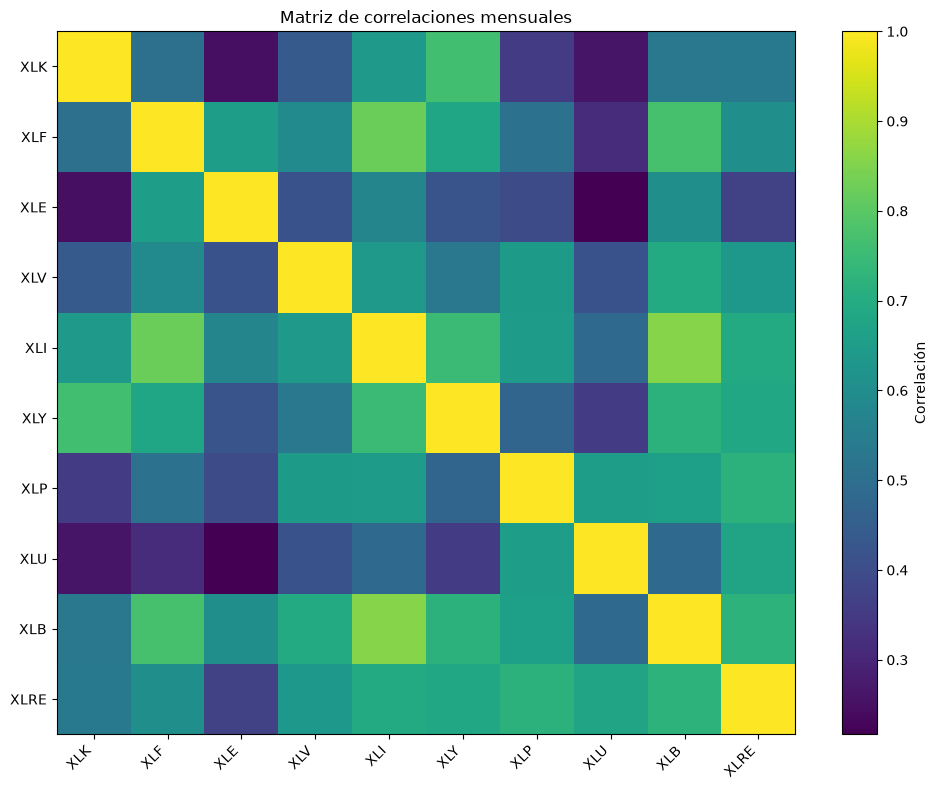

In [336]:
fig, ax = plt.subplots(
    figsize=(10, 8)
)

image = ax.imshow(
    correlation_matrix,
    aspect="auto",
)

ax.set_xticks(
    range(len(correlation_matrix.columns))
)
ax.set_xticklabels(
    correlation_matrix.columns,
    rotation=45,
    ha="right",
)

ax.set_yticks(
    range(len(correlation_matrix.index))
)
ax.set_yticklabels(
    correlation_matrix.index
)

ax.set_title(
    "Matriz de correlaciones mensuales"
)

fig.colorbar(
    image,
    ax=ax,
    label="Correlación",
)

plt.tight_layout()
plt.show()

### Interpretación

Las rentabilidades esperadas presentan diferencias importantes entre sectores.

`XLK` destaca claramente por su mayor rentabilidad histórica esperada dentro de la muestra común, mientras que `XLRE`, `XLP` y `XLU` presentan expectativas inferiores.

Sin embargo, la optimización no depende únicamente de la rentabilidad esperada individual. La estructura de covarianzas es igualmente importante, ya que permite combinar activos con comportamientos diferentes para reducir el riesgo total de cartera.

Por este motivo, un activo con menor rentabilidad esperada puede recibir un peso elevado si contribuye significativamente a la diversificación.

## 3. Carteras de referencia

A partir de los retornos esperados y de la matriz de covarianzas se construyen tres carteras:

1. **Minimum Variance**: minimiza la varianza total.
2. **Maximum Sharpe**: maximiza la relación rentabilidad-riesgo.
3. **Equal Weight**: asigna el mismo peso a cada sector y sirve como referencia simple.

En esta primera comparación se utilizan restricciones long-only, sin límite máximo de peso por activo.

In [337]:
weights_min_variance = min_variance(
    covariance_matrix,
)

weights_max_sharpe = max_sharpe(
    expected_returns,
    covariance_matrix,
)

weights_equal = pd.Series(
    1.0 / len(SECTOR_TICKERS),
    index=SECTOR_TICKERS,
    name="weight",
)

weights_equal = weights_equal.reindex(
    covariance_matrix.index
)

In [338]:
weights_table = pd.DataFrame(
    {
        "Minimum Variance": weights_min_variance * 100,
        "Maximum Sharpe": weights_max_sharpe * 100,
        "Equal Weight": weights_equal * 100,
    }
)

weights_table.round(2)

,Minimum Variance,Maximum Sharpe,Equal Weight
XLK,11.08,53.40,10.0
XLF,0.70,0.00,10.0
XLE,0.00,4.98,10.0
XLV,27.28,15.79,10.0
XLI,0.00,0.00,10.0
XLY,0.00,0.00,10.0
XLP,37.93,0.00,10.0
XLU,23.01,25.83,10.0
XLB,0.00,0.00,10.0
XLRE,0.00,0.00,10.0


In [339]:
def portfolio_stats(
    weights,
    expected_returns,
    covariance_matrix,
):
    expected_return = portfolio_return(
        weights.to_numpy(),
        expected_returns,
    )

    volatility = portfolio_volatility(
        weights.to_numpy(),
        covariance_matrix,
    )

    sharpe = (
        expected_return / volatility
    )

    return pd.Series(
        {
            "Expected return %": expected_return * 100,
            "Volatility %": volatility * 100,
            "Sharpe": sharpe,
        }
    )

In [340]:
portfolio_comparison = pd.DataFrame(
    {
        "Minimum Variance": portfolio_stats(
            weights_min_variance,
            expected_returns,
            covariance_matrix,
        ),
        "Maximum Sharpe": portfolio_stats(
            weights_max_sharpe,
            expected_returns,
            covariance_matrix,
        ),
        "Equal Weight": portfolio_stats(
            weights_equal,
            expected_returns,
            covariance_matrix,
        ),
    }
).T

portfolio_comparison.round(3)

,Expected return %,Volatility %,Sharpe
Minimum Variance,11.308,11.769,0.961
Maximum Sharpe,17.308,14.438,1.199
Equal Weight,12.594,14.389,0.875


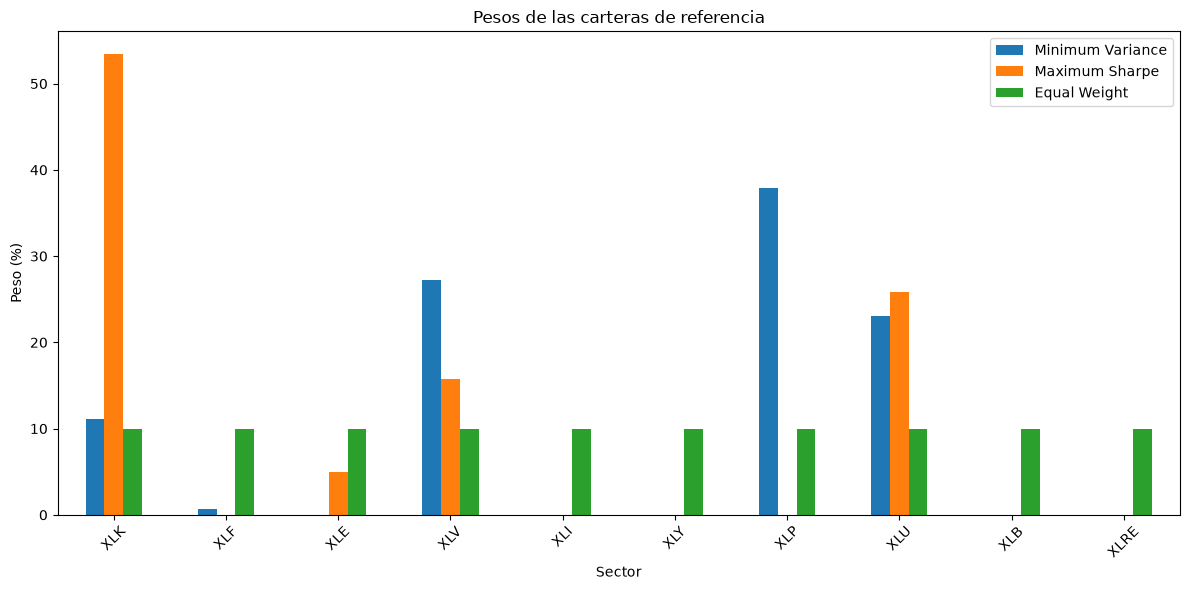

In [341]:
weights_table.plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title(
    "Pesos de las carteras de referencia"
)

plt.ylabel(
    "Peso (%)"
)

plt.xlabel(
    "Sector"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

### Interpretación

La cartera de máximo Sharpe presenta una concentración elevada en unos pocos sectores, especialmente `XLK` y `XLU`.

Esto muestra una característica clásica de la optimización media-varianza: pequeñas diferencias en las estimaciones de rentabilidad esperada y covarianza pueden producir soluciones extremas y altamente concentradas.

La cartera de mínima varianza, en cambio, prioriza sectores con menor contribución al riesgo total, mientras que Equal Weight evita completamente el error de estimación de pesos al distribuir el capital de manera uniforme.

Por tanto, la cartera con mejor Sharpe *in-sample* no tiene por qué ser la más robusta fuera de muestra.

## 4. Frontera eficiente y restricciones realistas

La frontera eficiente representa las carteras que ofrecen la mínima volatilidad posible para cada nivel de rentabilidad esperada.

Se comparan dos escenarios:

1. **Frontera sin límite individual de peso**, manteniendo únicamente la restricción long-only.
2. **Frontera con un máximo del 20% por activo**.

La segunda configuración representa una restricción más realista, ya que evita que la solución dependa excesivamente de uno o dos sectores.

In [342]:
frontier_free = efficient_frontier(
    expected_returns,
    covariance_matrix,
    n_points=50,
    long_only=True,
)

frontier_20 = efficient_frontier(
    expected_returns,
    covariance_matrix,
    n_points=50,
    long_only=True,
    max_weight=0.20,
)

print("Frontera libre:")
display(frontier_free.head())

print("\nFrontera max_weight=20%:")
display(frontier_20.head())

Frontera libre:


,return,volatility,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE
0,0.113076,0.117694,0.110787,0.007007,0.000000e+00,0.272789,3.514270e-18,2.117912e-17,0.379332,0.230086,7.970294e-18,0.000000e+00
1,0.115419,0.117740,0.127582,0.006326,0.000000e+00,0.271235,1.888433e-18,0.000000e+00,0.362280,0.232577,6.093350e-19,0.000000e+00
2,0.117761,0.117878,0.144378,0.005650,0.000000e+00,0.269669,0.000000e+00,0.000000e+00,0.345231,0.235072,1.315452e-18,0.000000e+00
3,0.120103,0.118109,0.161173,0.004974,1.304822e-17,0.268106,0.000000e+00,4.139172e-19,0.328182,0.237564,0.000000e+00,1.803413e-18
4,0.122446,0.118431,0.177969,0.004297,1.309539e-17,0.266546,0.000000e+00,0.000000e+00,0.311132,0.240057,4.402333e-18,0.000000e+00



Frontera max_weight=20%:


,return,volatility,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE
0,0.127027,0.123906,0.183653,0.146279,0.002508,0.2,1.812227e-17,0.000000e+00,0.2,0.2,0.000000e+00,0.067559
1,0.127574,0.123908,0.187155,0.146065,0.002985,0.2,0.000000e+00,3.138257e-19,0.2,0.2,2.488583e-18,0.063795
2,0.128121,0.123913,0.190657,0.145852,0.003460,0.2,2.436067e-18,9.723938e-19,0.2,0.2,0.000000e+00,0.060031
3,0.128668,0.123922,0.194160,0.145638,0.003935,0.2,2.744387e-19,0.000000e+00,0.2,0.2,4.064911e-18,0.056267
4,0.129215,0.123934,0.197662,0.145425,0.004410,0.2,1.058791e-18,7.098136e-19,0.2,0.2,0.000000e+00,0.052503


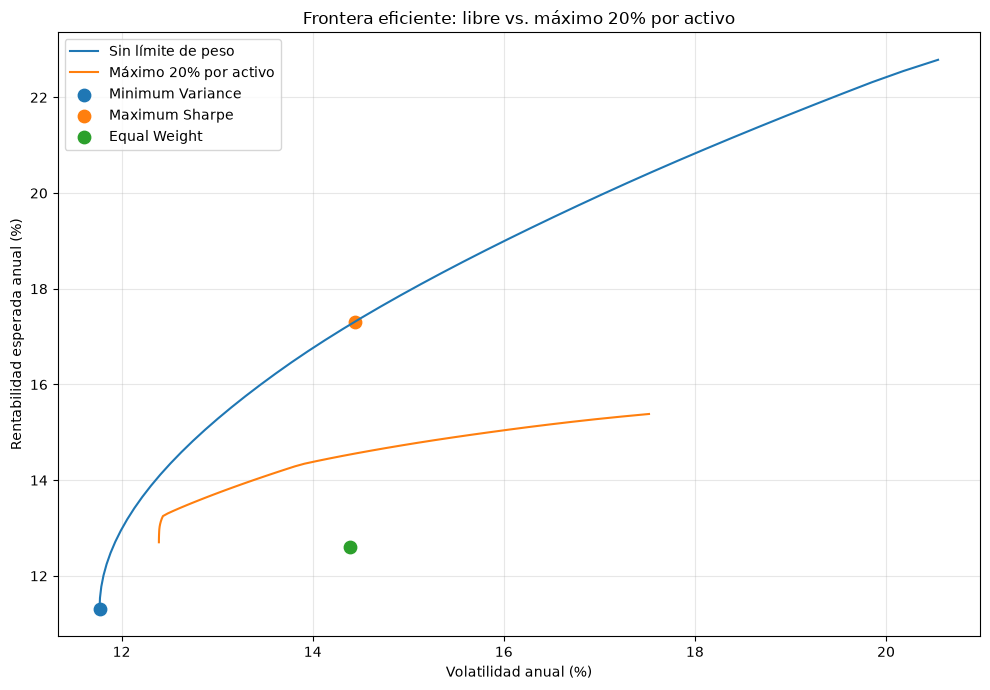

In [343]:

fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.plot(
    frontier_free["volatility"] * 100,
    frontier_free["return"] * 100,
    label="Sin límite de peso",
)

ax.plot(
    frontier_20["volatility"] * 100,
    frontier_20["return"] * 100,
    label="Máximo 20% por activo",
)

ax.scatter(
    portfolio_comparison.loc[
        "Minimum Variance",
        "Volatility %",
    ],
    portfolio_comparison.loc[
        "Minimum Variance",
        "Expected return %",
    ],
    s=80,
    label="Minimum Variance",
)

ax.scatter(
    portfolio_comparison.loc[
        "Maximum Sharpe",
        "Volatility %",
    ],
    portfolio_comparison.loc[
        "Maximum Sharpe",
        "Expected return %",
    ],
    s=80,
    label="Maximum Sharpe",
)

ax.scatter(
    portfolio_comparison.loc[
        "Equal Weight",
        "Volatility %",
    ],
    portfolio_comparison.loc[
        "Equal Weight",
        "Expected return %",
    ],
    s=80,
    label="Equal Weight",
)

ax.set_title(
    "Frontera eficiente: libre vs. máximo 20% por activo"
)

ax.set_xlabel(
    "Volatilidad anual (%)"
)

ax.set_ylabel(
    "Rentabilidad esperada anual (%)"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()


In [344]:
weights_max_sharpe_20 = max_sharpe(
    expected_returns,
    covariance_matrix,
    long_only=True,
    max_weight=0.20,
)

max_sharpe_20_stats = portfolio_stats(
    weights_max_sharpe_20,
    expected_returns,
    covariance_matrix,
)

max_sharpe_20_stats

Expected return %    13.271946
Volatility %         12.447995
Sharpe                1.066191
dtype: float64

In [345]:
weight_constraint_comparison = pd.DataFrame(
    {
        "Maximum Sharpe libre": (
            weights_max_sharpe * 100
        ),
        "Maximum Sharpe max 20%": (
            weights_max_sharpe_20 * 100
        ),
    }
)

weight_constraint_comparison.round(2)

,Maximum Sharpe libre,Maximum Sharpe max 20%
XLK,53.40,20.00
XLF,0.00,16.64
XLE,4.98,3.36
XLV,15.79,20.00
XLI,0.00,0.00
XLY,0.00,0.00
XLP,0.00,20.00
XLU,25.83,20.00
XLB,0.00,0.00
XLRE,0.00,0.00


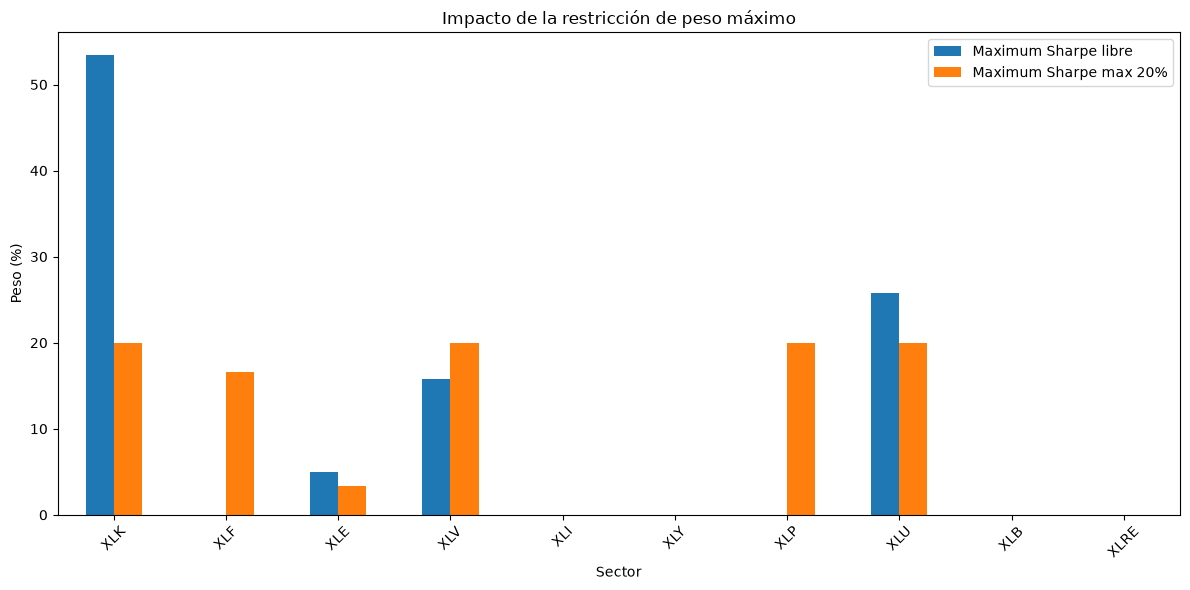

In [346]:
weight_constraint_comparison.plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title(
    "Impacto de la restricción de peso máximo"
)

plt.ylabel(
    "Peso (%)"
)

plt.xlabel(
    "Sector"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [347]:
constraint_stats = pd.DataFrame(
    {
        "Max Sharpe libre": portfolio_stats(
            weights_max_sharpe,
            expected_returns,
            covariance_matrix,
        ),
        "Max Sharpe max 20%": portfolio_stats(
            weights_max_sharpe_20,
            expected_returns,
            covariance_matrix,
        ),
    }
).T

constraint_stats.round(3)

,Expected return %,Volatility %,Sharpe
Max Sharpe libre,17.308,14.438,1.199
Max Sharpe max 20%,13.272,12.448,1.066


In [348]:
concentration = pd.DataFrame(
    {
        "Largest weight %": [
            weights_max_sharpe.max() * 100,
            weights_max_sharpe_20.max() * 100,
        ],
        "Top 2 weights %": [
            (
                weights_max_sharpe
                .nlargest(2)
                .sum()
                * 100
            ),
            (
                weights_max_sharpe_20
                .nlargest(2)
                .sum()
                * 100
            ),
        ],
        "Number active": [
            (
                weights_max_sharpe
                > 1e-6
            ).sum(),
            (
                weights_max_sharpe_20
                > 1e-6
            ).sum(),
        ],
    },
    index=[
        "Max Sharpe libre",
        "Max Sharpe max 20%",
    ],
)

concentration.round(2)

,Largest weight %,Top 2 weights %,Number active
Max Sharpe libre,53.4,79.22,4
Max Sharpe max 20%,20.0,40.00,6


### Impacto de la restricción de peso máximo

La frontera con un límite del 20% se sitúa dentro del conjunto alcanzable por la optimización sin restricciones. Esto es esperable: al introducir restricciones se reduce el conjunto de carteras factibles.

La cartera Maximum Sharpe sin límite presenta una concentración muy elevada, principalmente en `XLK` y `XLU`, que conjuntamente representan alrededor del 80% de la cartera.

Al imponer un máximo del 20% por activo:

- disminuye la concentración;
- aumenta el número de posiciones relevantes;
- disminuye el Sharpe esperado *in-sample*;
- se obtiene una cartera económicamente más diversificada.

Este resultado ilustra un problema clásico de Markowitz: la optimización puede explotar agresivamente pequeñas diferencias en las estimaciones de rentabilidad y covarianza, generando pesos extremos. Las restricciones realistas sacrifican parte del óptimo matemático a cambio de mayor robustez y diversificación.

## 5. Restricción de turnover

Además de limitar el peso máximo por activo, una cartera realista debe controlar cuánto cambia respecto a su composición anterior.

Definimos el turnover como:

\[
\sum_i |w_i - w_i^{prev}|
\]

y limitamos su valor máximo al 20%.

Para ilustrarlo, partimos de una cartera Equal Weight del 10% por sector y buscamos la cartera de máximo Sharpe compatible con ese límite.

In [349]:
previous_weights = pd.Series(
    1.0 / len(SECTOR_TICKERS),
    index=SECTOR_TICKERS,
    name="previous_weight",
)

previous_weights = previous_weights.reindex(
    expected_returns.index
)

weights_turnover_20 = max_sharpe(
    expected_returns,
    covariance_matrix,
    previous_weights=previous_weights,
    turnover_limit=0.20,
)

realized_turnover = (
    np.abs(
        weights_turnover_20
        - previous_weights
    ).sum()
)

print(
    "Turnover:",
    round(
        realized_turnover * 100,
        3,
    ),
    "%",
)

Turnover: 20.0 %


In [350]:
turnover_weights_table = pd.DataFrame(
    {
        "Equal Weight inicial": (
            previous_weights * 100
        ),
        "Max Sharpe turnover 20%": (
            weights_turnover_20 * 100
        ),
        "Max Sharpe libre": (
            weights_max_sharpe * 100
        ),
    }
)

turnover_weights_table.round(2)

,Equal Weight inicial,Max Sharpe turnover 20%,Max Sharpe libre
XLK,10.0,20.0,53.40
XLF,10.0,10.0,0.00
XLE,10.0,10.0,4.98
XLV,10.0,10.0,15.79
XLI,10.0,10.0,0.00
XLY,10.0,10.0,0.00
XLP,10.0,10.0,0.00
XLU,10.0,10.0,25.83
XLB,10.0,10.0,0.00
XLRE,10.0,0.0,0.00


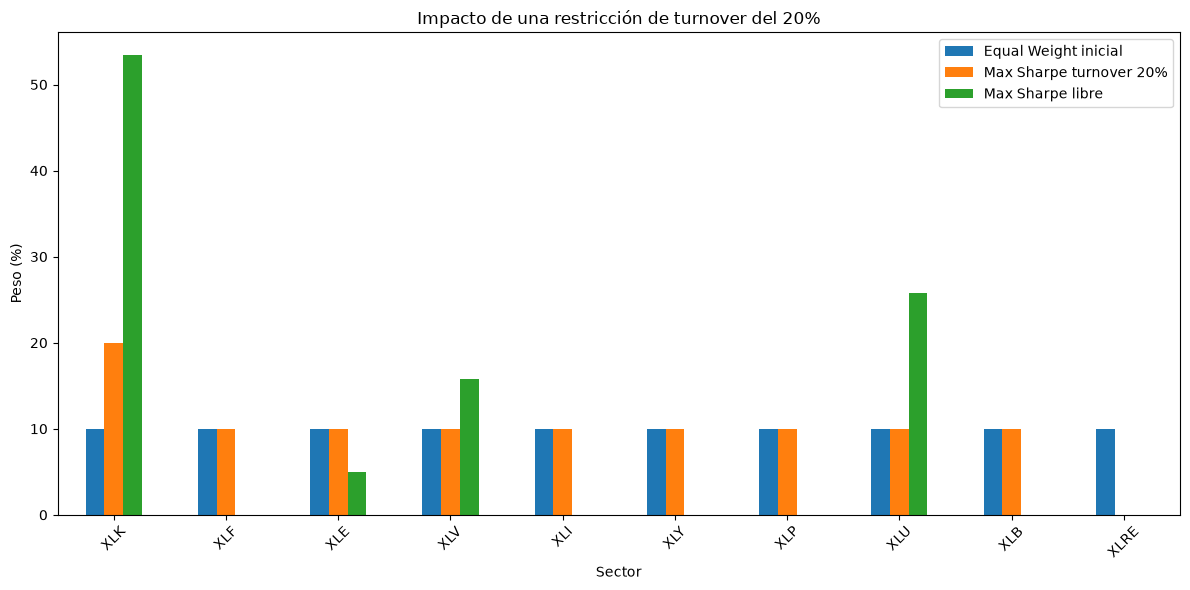

In [351]:
turnover_weights_table.plot(
    kind="bar",
    figsize=(12, 6),
)

plt.title(
    "Impacto de una restricción de turnover del 20%"
)

plt.ylabel(
    "Peso (%)"
)

plt.xlabel(
    "Sector"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [352]:
turnover_stats = pd.DataFrame(
    {
        "Equal Weight": portfolio_stats(
            previous_weights,
            expected_returns,
            covariance_matrix,
        ),
        "Max Sharpe turnover 20%": portfolio_stats(
            weights_turnover_20,
            expected_returns,
            covariance_matrix,
        ),
        "Max Sharpe libre": portfolio_stats(
            weights_max_sharpe,
            expected_returns,
            covariance_matrix,
        ),
    }
).T

turnover_stats.round(3)

,Expected return %,Volatility %,Sharpe
Equal Weight,12.594,14.389,0.875
Max Sharpe turnover 20%,14.098,14.501,0.972
Max Sharpe libre,17.308,14.438,1.199


### Interpretación

La restricción de turnover limita la distancia entre la cartera inicial y la nueva cartera óptima.

Partiendo de Equal Weight, el optimizador utiliza completamente el límite del 20%:

- reduce aproximadamente 10 puntos porcentuales de `XLRE`;
- aumenta aproximadamente 10 puntos porcentuales en `XLK`;
- mantiene el resto de posiciones prácticamente sin cambios.

La cartera mejora su Sharpe esperado respecto a Equal Weight, pero no puede alcanzar la solución extrema del Maximum Sharpe sin restricciones.

Este resultado muestra que `max_weight` y `turnover` controlan riesgos diferentes:

- `max_weight` limita la concentración absoluta de la cartera;
- `turnover` limita cuánto puede cambiar la cartera respecto a su posición actual.

En una implementación real, el turnover también está directamente relacionado con costes de transacción, impacto de mercado y estabilidad operativa.

## 6. CAPM y Security Market Line

El CAPM relaciona la rentabilidad esperada de un activo con su exposición al riesgo sistemático de mercado.

El beta de cada sector se estima frente a `SPY` como:

\[
\beta_i =
\frac{\operatorname{Cov}(R_i,R_m)}
{\operatorname{Var}(R_m)}
\]

A partir de los betas sectoriales se estima también una Security Market Line empírica mediante una regresión transversal:

\[
\bar{R}_i = a + \lambda \beta_i + \varepsilon_i
\]

donde:

- \(a\) es el intercepto de la SML;
- \(\lambda\) mide cuánto retorno adicional se ha asociado históricamente con una unidad adicional de beta.

In [353]:
sector_returns = returns[
    SECTOR_TICKERS
]

spy_returns = returns[
    MARKET_TICKER
]

sector_betas = estimate_sector_betas(
    sector_returns,
    spy_returns,
)

sector_betas.sort_values()

XLU     0.414338
XLP     0.561088
XLV     0.687307
XLRE    0.850367
XLF     1.082100
XLB     1.092599
XLI     1.107016
XLE     1.113529
XLK     1.146543
XLY     1.147904
Name: beta, dtype: float64

In [354]:
sml = estimate_sml(
    sector_returns,
    spy_returns,
    periods_per_year=PERIODS_PER_YEAR,
)

sml_table = sml.copy()

sml_table["annual_return_%"] = (
    sml_table["annual_return"] * 100
)

sml_table["sml_fitted_return_%"] = (
    sml_table["sml_fitted_return"] * 100
)

sml_table["return_minus_sml_%"] = (
    sml_table["annual_return_%"]
    - sml_table["sml_fitted_return_%"]
)

sml_table = sml_table[
    [
        "beta",
        "annual_return_%",
        "sml_fitted_return_%",
        "return_minus_sml_%",
    ]
].sort_values(
    "beta"
)

sml_table.round(3)

,beta,annual_return_%,sml_fitted_return_%,return_minus_sml_%
XLU,0.414,10.694,9.637,1.057
XLP,0.561,10.684,10.572,0.112
XLV,0.687,13.124,11.376,1.748
XLRE,0.850,7.753,12.415,-4.662
XLF,1.082,12.941,13.892,-0.951
XLB,1.093,11.224,13.959,-2.735
XLI,1.107,14.257,14.051,0.206
XLE,1.114,12.285,14.093,-1.808
XLK,1.147,20.296,14.303,5.993
XLY,1.148,15.351,14.312,1.039


In [355]:
sml_intercept = (
    sml.attrs["intercept"]
)

sml_slope = (
    sml.attrs["slope"]
)

print(
    "Intercepto anual:",
    round(
        sml_intercept * 100,
        3,
    ),
    "%",
)

print(
    "Pendiente anual:",
    round(
        sml_slope * 100,
        3,
    ),
    "%",
)

Intercepto anual: 6.996 %
Pendiente anual: 6.373 %


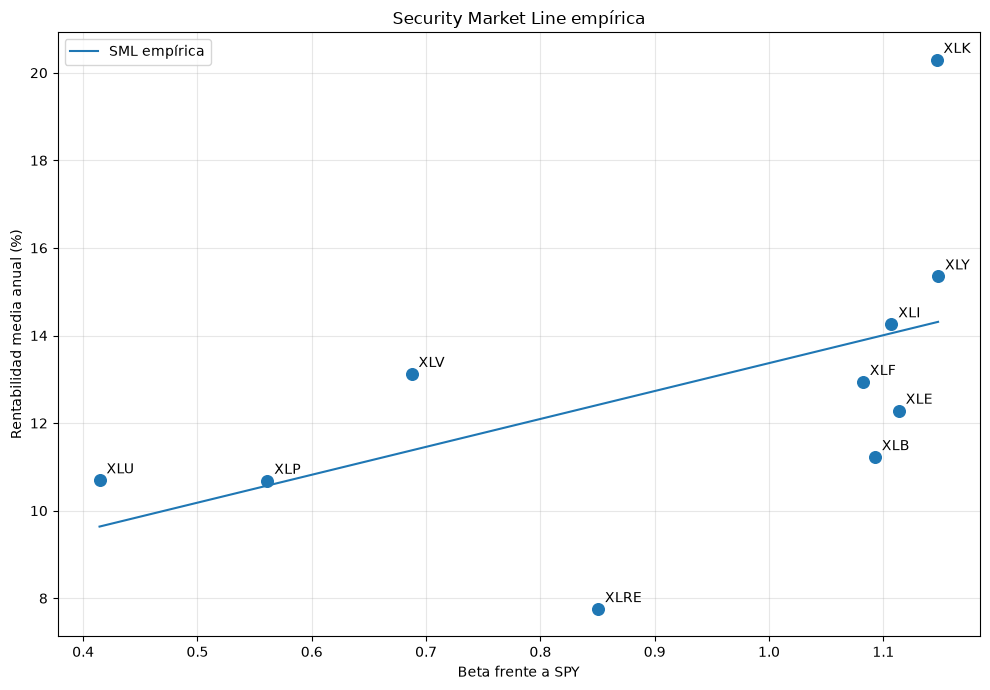

In [356]:
fig, ax = plt.subplots(
    figsize=(10, 7)
)

ax.scatter(
    sml_table["beta"],
    sml_table["annual_return_%"],
    s=70,
)

beta_grid = np.linspace(
    sml_table["beta"].min(),
    sml_table["beta"].max(),
    100,
)

sml_line = (
    sml_intercept
    + sml_slope * beta_grid
) * 100

ax.plot(
    beta_grid,
    sml_line,
    label="SML empírica",
)

for ticker, row in sml_table.iterrows():
    ax.annotate(
        ticker,
        (
            row["beta"],
            row["annual_return_%"],
        ),
        xytext=(5, 5),
        textcoords="offset points",
    )

ax.set_title(
    "Security Market Line empírica"
)

ax.set_xlabel(
    "Beta frente a SPY"
)

ax.set_ylabel(
    "Rentabilidad media anual (%)"
)

ax.grid(
    alpha=0.3
)

ax.legend()

plt.tight_layout()
plt.show()

### Interpretación de la SML

La pendiente estimada de la Security Market Line es positiva, lo que indica que, dentro de esta muestra, los sectores con mayor beta han tendido a presentar una mayor rentabilidad media.

Sin embargo, la dispersión alrededor de la recta es considerable, por lo que el beta de mercado no explica por sí solo las diferencias de rentabilidad entre sectores.

Destacan especialmente:

- `XLU`, con un beta cercano a 0,41, como uno de los sectores más defensivos;
- `XLP`, también con beta claramente inferior a uno;
- `XLK`, con beta superior a uno y una rentabilidad muy por encima de la SML estimada;
- `XLRE`, con una rentabilidad claramente inferior a la asociada a su beta.

La diferencia entre rentabilidad observada y SML no debe interpretarse todavía como alpha multifactorial. Se trata únicamente de una desviación respecto a una relación transversal estimada entre beta y retorno medio.

In [357]:
sector_common = (
    returns[SECTOR_TICKERS]
    .dropna()
)

spy_common = (
    returns[MARKET_TICKER]
    .reindex(
        sector_common.index
    )
    .dropna()
)

sector_common = (
    sector_common
    .reindex(
        spy_common.index
    )
)

max_sharpe_realized = (
    sector_common
    @ weights_max_sharpe.reindex(
        sector_common.columns
    )
)

equal_weight_realized = (
    sector_common
    @ weights_equal.reindex(
        sector_common.columns
    )
)

comparison_returns = pd.DataFrame(
    {
        "Max Sharpe": max_sharpe_realized,
        "Equal Weight": equal_weight_realized,
        "SPY": spy_common,
    }
).dropna()

In [358]:
def realized_statistics(
    return_series,
    periods_per_year=12,
):
    annual_return = (
        return_series.mean()
        * periods_per_year
    )

    annual_volatility = (
        return_series.std(ddof=1)
        * np.sqrt(periods_per_year)
    )

    sharpe = (
        annual_return
        / annual_volatility
    )

    cumulative = (
        1.0 + return_series
    ).cumprod()

    drawdown = (
        cumulative
        / cumulative.cummax()
        - 1.0
    )

    return pd.Series(
        {
            "Return %": annual_return * 100,
            "Volatility %": annual_volatility * 100,
            "Sharpe": sharpe,
            "Max Drawdown %": (
                drawdown.min() * 100
            ),
        }
    )


comparison_realized = (
    comparison_returns
    .apply(
        realized_statistics
    )
    .T
)

comparison_realized.round(3)

,Return %,Volatility %,Sharpe,Max Drawdown %
Max Sharpe,17.308,14.438,1.199,-19.609
Equal Weight,12.594,14.389,0.875,-23.167
SPY,14.698,14.893,0.987,-23.927


### Comparación in-sample

La cartera Maximum Sharpe presenta mejores métricas históricas que Equal Weight y SPY dentro de la muestra utilizada para estimar sus pesos.

Sin embargo, esta comparación es **in-sample**: los mismos datos han servido tanto para estimar la cartera como para evaluar su resultado.

Por tanto, el Sharpe superior no constituye evidencia suficiente de robustez. La siguiente sección realiza una validación out-of-sample separando explícitamente el periodo de estimación y el periodo de evaluación.

## 7. Validación out-of-sample

Para evaluar la robustez de la optimización media-varianza se separa explícitamente el periodo de estimación del periodo de evaluación.

Se utiliza:

- **Train:** 2010–2017
- **Test:** 2019–actualidad

El año 2018 se deja fuera siguiendo la especificación de la práctica.

Dado que `XLRE` no dispone de datos desde 2010, esta validación utiliza los otros nueve ETFs sectoriales. Esto permite conservar la mayor parte de la ventana histórica de entrenamiento sin imputar datos inexistentes.

In [359]:
OOS_TICKERS = [
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLI",
    "XLY",
    "XLP",
    "XLU",
    "XLB",
]

train_returns = (
    returns.loc[
        "2010-01-01":"2017-12-31",
        OOS_TICKERS,
    ]
    .dropna()
)

test_returns = (
    returns.loc[
        "2019-01-01":,
        OOS_TICKERS + [MARKET_TICKER],
    ]
    .dropna()
)

print(
    "Train:",
    train_returns.index.min(),
    "->",
    train_returns.index.max(),
    "|",
    len(train_returns),
    "observaciones",
)

print(
    "Test:",
    test_returns.index.min(),
    "->",
    test_returns.index.max(),
    "|",
    len(test_returns),
    "observaciones",
)

Train: 2010-02-01 00:00:00 -> 2017-12-01 00:00:00 | 95 observaciones
Test: 2019-01-01 00:00:00 -> 2026-10-01 00:00:00 | 94 observaciones


In [360]:
expected_returns_train, covariance_train = estimate_inputs(
    train_returns,
    periods_per_year=PERIODS_PER_YEAR,
)

weights_max_sharpe_train = max_sharpe(
    expected_returns_train,
    covariance_train,
)

weights_equal_train = pd.Series(
    1.0 / len(OOS_TICKERS),
    index=OOS_TICKERS,
    name="weight",
)

weights_max_sharpe_train = (
    weights_max_sharpe_train
    .reindex(train_returns.columns)
)

weights_equal_train = (
    weights_equal_train
    .reindex(train_returns.columns)
)

pd.DataFrame(
    {
        "Max Sharpe train %": weights_max_sharpe_train * 100,
        "Equal Weight %": weights_equal_train * 100,
    }
).round(2)

,Max Sharpe train %,Equal Weight %
XLK,11.90,11.11
XLF,0.00,11.11
XLE,0.00,11.11
XLV,22.13,11.11
XLI,0.00,11.11
XLY,29.17,11.11
XLP,3.64,11.11
XLU,33.16,11.11
XLB,0.00,11.11


In [361]:
expected_train_stats = portfolio_stats(
    weights_max_sharpe_train,
    expected_returns_train,
    covariance_train,
)

expected_train_stats

Expected return %    14.960672
Volatility %          9.674546
Sharpe                1.546395
dtype: float64

In [362]:
sector_test_returns = test_returns[
    OOS_TICKERS
]

spy_test_returns = test_returns[
    MARKET_TICKER
]

max_sharpe_oos_returns = (
    sector_test_returns
    @ weights_max_sharpe_train
)

equal_weight_oos_returns = (
    sector_test_returns
    @ weights_equal_train
)

oos_returns = pd.DataFrame(
    {
        "Max Sharpe OOS": max_sharpe_oos_returns,
        "Equal Weight": equal_weight_oos_returns,
        "SPY": spy_test_returns,
    }
)

oos_returns.head()

,Max Sharpe OOS,Equal Weight,SPY
Date,,,
2019-01-01,0.061080,0.074857,0.080066
2019-02-01,0.028724,0.032543,0.032416
2019-03-01,0.028052,0.016881,0.018101
2019-04-01,0.021620,0.032610,0.040852
2019-05-01,-0.041322,-0.063341,-0.063771


In [363]:
oos_stats = (
    oos_returns
    .apply(
        realized_statistics
    )
    .T
)

oos_stats.round(3)

,Return %,Volatility %,Sharpe,Max Drawdown %
Max Sharpe OOS,13.758,14.456,0.952,-18.134
Equal Weight,15.327,15.852,0.967,-23.599
SPY,17.221,16.290,1.057,-23.927


In [364]:
expected_vs_realized = pd.DataFrame(
    {
        "Expected in-sample": {
            "Return %": expected_train_stats[
                "Expected return %"
            ],
            "Volatility %": expected_train_stats[
                "Volatility %"
            ],
            "Sharpe": expected_train_stats[
                "Sharpe"
            ],
        },
        "Realized OOS": {
            "Return %": oos_stats.loc[
                "Max Sharpe OOS",
                "Return %",
            ],
            "Volatility %": oos_stats.loc[
                "Max Sharpe OOS",
                "Volatility %",
            ],
            "Sharpe": oos_stats.loc[
                "Max Sharpe OOS",
                "Sharpe",
            ],
        },
    }
).T

expected_vs_realized.round(3)

,Return %,Volatility %,Sharpe
Expected in-sample,14.961,9.675,1.546
Realized OOS,13.758,14.456,0.952


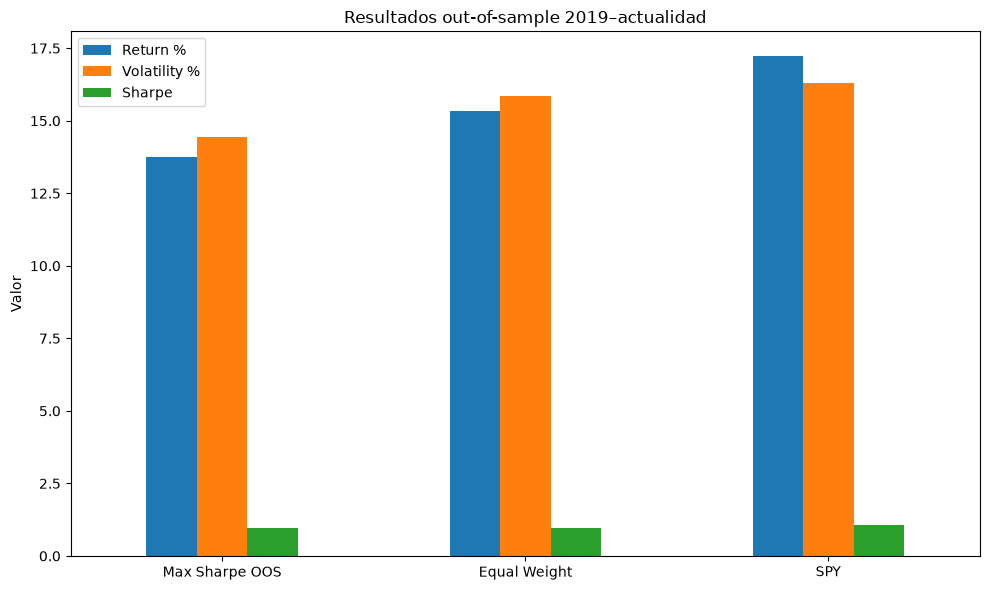

In [365]:
oos_stats[
    [
        "Return %",
        "Volatility %",
        "Sharpe",
    ]
].plot(
    kind="bar",
    figsize=(10, 6),
)

plt.title(
    "Resultados out-of-sample 2019–actualidad"
)

plt.ylabel(
    "Valor"
)

plt.xticks(
    rotation=0
)

plt.tight_layout()
plt.show()

### Interpretación out-of-sample

La cartera Maximum Sharpe estimada con datos de 2010–2017 no mantiene fuera de muestra la superioridad observada durante el entrenamiento.

Durante el periodo de estimación se esperaba aproximadamente:

- rentabilidad anual cercana al 15%;
- volatilidad inferior al 10%;
- Sharpe alrededor de 1,55.

Sin embargo, durante 2019–actualidad:

- la rentabilidad realizada es inferior a la esperada;
- la volatilidad aumenta de forma muy significativa;
- el Sharpe cae hasta aproximadamente 0,95.

Además, tanto Equal Weight como SPY obtienen un Sharpe similar o superior durante el periodo out-of-sample.

El principal error de estimación aparece en el riesgo: la volatilidad realizada resulta muy superior a la prevista por la matriz de covarianzas histórica.

Este resultado ilustra una de las principales limitaciones de Markowitz: los pesos óptimos pueden ser muy sensibles a los parámetros estimados y una solución excelente in-sample puede perder gran parte de su ventaja cuando cambian las condiciones de mercado.

## 8. Modelos multifactoriales

Se estiman cuatro modelos para los 10 sectores y para dos carteras de referencia:

- CAPM
- Fama-French 3 factores
- Carhart 4 factores
- Fama-French 5 factores

La regresión general es:

$$
R_{i,t} - R_{f,t}
=
\alpha_i
+
\beta_1 F_{1,t}
+
\cdots
+
\beta_k F_{k,t}
+
\varepsilon_t
$$

donde:

- $R_{i,t}$ es la rentabilidad del activo o cartera;
- $R_{f,t}$ es la tasa libre de riesgo;
- $\alpha_i$ representa el retorno no explicado por los factores;
- $\beta_k$ mide la sensibilidad al factor $k$;
- $F_{k,t}$ representa cada factor de riesgo;
- $\varepsilon_t$ es el término residual.

Se analizan:

- alpha anualizado;
- t-stat del alpha;
- betas factoriales;
- R² ajustado.

El objetivo es comprobar si el alpha observado bajo CAPM sobrevive al introducir factores adicionales.

In [366]:
factors = load_fama_french_factors(
    start=START_DATE,
)

factors.head()

,Mkt-RF,SMB,HML,RMW,CMA,Mom,RF
Date,,,,,,,
2010-01-01,-0.0335,0.0040,0.0033,-0.0108,0.0050,-0.0531,0.0000
2010-02-01,0.0339,0.0149,0.0318,-0.0029,0.0142,0.0370,0.0000
2010-03-01,0.0630,0.0183,0.0219,-0.0061,0.0174,0.0358,0.0001
2010-04-01,0.0200,0.0496,0.0296,0.0061,0.0174,0.0319,0.0001
2010-05-01,-0.0790,0.0008,-0.0248,0.0130,-0.0023,-0.0018,0.0001


In [367]:
common_factor_returns = (
    returns[SECTOR_TICKERS]
    .dropna()
)

max_sharpe_factor_returns = (
    common_factor_returns
    @ weights_max_sharpe.reindex(
        common_factor_returns.columns
    )
)

equal_weight_factor_returns = (
    common_factor_returns
    @ weights_equal.reindex(
        common_factor_returns.columns
    )
)

assets_for_factors = {
    ticker: returns[ticker]
    for ticker in SECTOR_TICKERS
}

assets_for_factors[
    "Max Sharpe"
] = max_sharpe_factor_returns

assets_for_factors[
    "Equal Weight"
] = equal_weight_factor_returns

In [368]:
factor_models = [
    "capm",
    "ff3",
    "carhart4",
    "ff5",
]

factor_rows = []

for asset_name, asset_returns in assets_for_factors.items():
    for model in factor_models:
        result = run_factor_regression(
            asset_returns,
            factors,
            model=model,
        )

        factor_rows.append(
            {
                "asset": asset_name,
                "model": model,
                **result.to_dict(),
            }
        )

factor_results = pd.DataFrame(
    factor_rows
)

factor_results[
    "alpha_annual_%"
] = (
    factor_results[
        "alpha_annual"
    ]
    * 100
)

factor_results.head()

,asset,model,alpha_annual,alpha_tstat,beta_Mkt-RF,tstat_Mkt-RF,adj_r_squared,n_obs,beta_SMB,tstat_SMB,beta_HML,tstat_HML,beta_Mom,tstat_Mom,beta_RMW,tstat_RMW,beta_CMA,tstat_CMA,alpha_annual_%
0,XLK,capm,0.044552,1.937265,1.093141,25.284193,0.763240,199.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.455248
1,XLK,ff3,0.029845,1.590440,1.167066,31.333136,0.844491,199.0,-0.326203,-5.183430,-0.323236,-6.575166,NaN,NaN,NaN,NaN,NaN,NaN,2.984478
2,XLK,carhart4,0.028477,1.502937,1.171526,30.742122,0.843956,199.0,-0.321085,-5.043355,-0.317217,-6.300984,0.025598,0.57522,NaN,NaN,NaN,NaN,2.847657
3,XLK,ff5,0.036552,1.997737,1.150939,31.318152,0.853588,199.0,-0.403539,-6.215546,-0.210959,-3.380064,NaN,NaN,-0.205404,-2.920524,-0.186189,-2.021012,3.655209
4,XLF,capm,-0.022669,-0.916494,1.052133,22.626492,0.720717,199.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-2.266936


In [369]:
alpha_table = factor_results.pivot(
    index="asset",
    columns="model",
    values="alpha_annual_%",
)

alpha_table = alpha_table[
    [
        "capm",
        "ff3",
        "carhart4",
        "ff5",
    ]
]

alpha_table.round(3)

model,capm,ff3,carhart4,ff5
asset,,,,
Equal Weight,-0.458,-0.691,-0.609,-1.088
Max Sharpe,4.228,3.271,2.956,3.206
XLB,-4.073,-3.589,-2.924,-4.529
XLE,-4.063,-2.316,-0.781,-3.307
XLF,-2.267,-1.614,-1.244,-1.044
XLI,-1.100,-0.462,-0.780,-1.082
XLK,4.455,2.984,2.848,3.655
XLP,2.215,1.021,0.684,-0.703
XLRE,-4.186,-4.053,-4.057,-4.675


In [370]:
alpha_tstat_table = factor_results.pivot(
    index="asset",
    columns="model",
    values="alpha_tstat",
)

alpha_tstat_table = alpha_tstat_table[
    [
        "capm",
        "ff3",
        "carhart4",
        "ff5",
    ]
]

alpha_tstat_table.round(3)

model,capm,ff3,carhart4,ff5
asset,,,,
Equal Weight,-0.290,-0.532,-0.466,-0.945
Max Sharpe,2.510,2.228,2.058,2.201
XLB,-1.551,-1.460,-1.191,-1.898
XLE,-0.756,-0.543,-0.185,-0.779
XLF,-0.916,-0.925,-0.711,-0.614
XLI,-0.555,-0.257,-0.431,-0.614
XLK,1.937,1.590,1.503,1.998
XLP,0.926,0.451,0.300,-0.369
XLRE,-1.155,-1.103,-1.097,-1.312


In [371]:
r2_table = factor_results.pivot(
    index="asset",
    columns="model",
    values="adj_r_squared",
)

r2_table = r2_table[
    [
        "capm",
        "ff3",
        "carhart4",
        "ff5",
    ]
]

r2_table.round(3)

model,capm,ff3,carhart4,ff5
asset,,,,
Equal Weight,0.876,0.918,0.918,0.936
Max Sharpe,0.862,0.897,0.902,0.899
XLB,0.697,0.738,0.742,0.755
XLE,0.369,0.608,0.623,0.616
XLF,0.721,0.863,0.864,0.871
XLI,0.807,0.843,0.843,0.851
XLK,0.763,0.844,0.844,0.854
XLP,0.397,0.467,0.468,0.626
XLRE,0.532,0.527,0.523,0.557


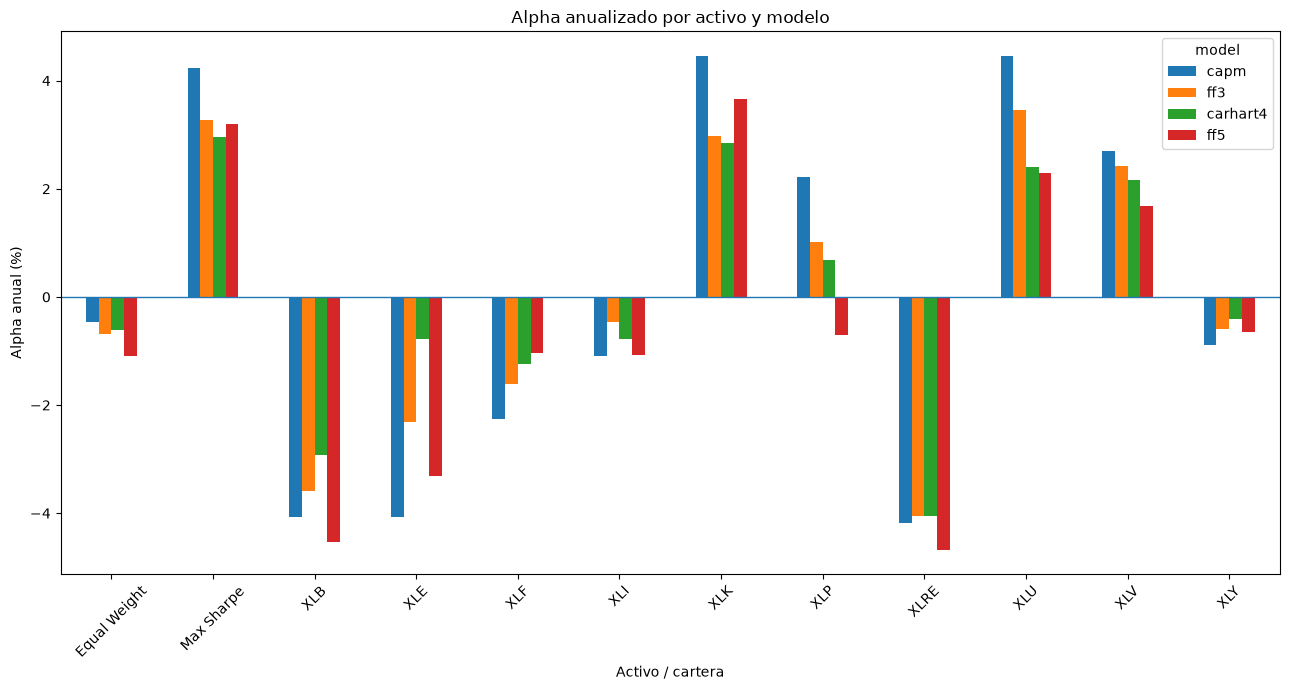

In [372]:
alpha_table.plot(
    kind="bar",
    figsize=(13, 7),
)

plt.title(
    "Alpha anualizado por activo y modelo"
)

plt.ylabel(
    "Alpha anual (%)"
)

plt.xlabel(
    "Activo / cartera"
)

plt.xticks(
    rotation=45
)

plt.axhline(
    0,
    linewidth=1,
)

plt.tight_layout()
plt.show()

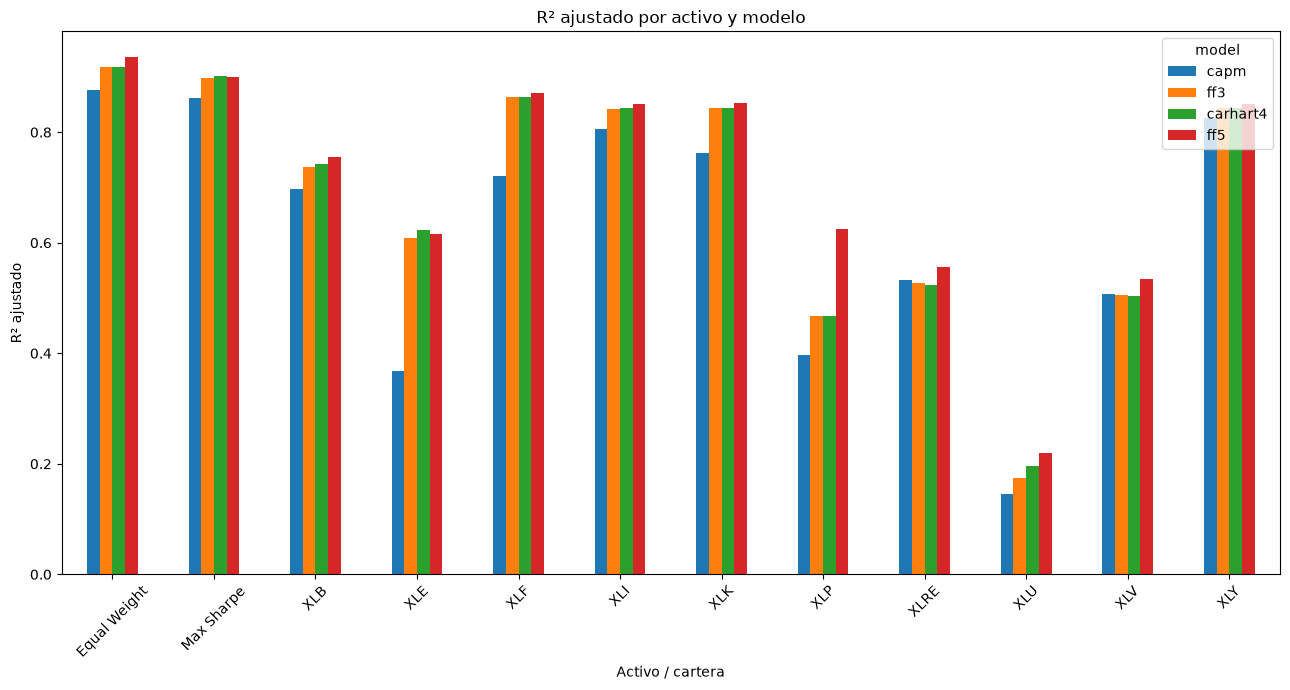

In [373]:
r2_table.plot(
    kind="bar",
    figsize=(13, 7),
)

plt.title(
    "R² ajustado por activo y modelo"
)

plt.ylabel(
    "R² ajustado"
)

plt.xlabel(
    "Activo / cartera"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

In [374]:
xlk_factor_results = (
    factor_results[
        factor_results["asset"] == "XLK"
    ]
    .set_index("model")
)

xlk_factor_results[
    [
        "alpha_annual_%",
        "alpha_tstat",
        "adj_r_squared",
        "beta_Mkt-RF",
        "beta_SMB",
        "beta_HML",
        "beta_Mom",
        "beta_RMW",
        "beta_CMA",
    ]
].round(3)

,alpha_annual_%,alpha_tstat,adj_r_squared,beta_Mkt-RF,beta_SMB,beta_HML,beta_Mom,beta_RMW,beta_CMA
model,,,,,,,,,
capm,4.455,1.937,0.763,1.093,NaN,NaN,NaN,NaN,NaN
ff3,2.984,1.590,0.844,1.167,-0.326,-0.323,NaN,NaN,NaN
carhart4,2.848,1.503,0.844,1.172,-0.321,-0.317,0.026,NaN,NaN
ff5,3.655,1.998,0.854,1.151,-0.404,-0.211,NaN,-0.205,-0.186


In [375]:
max_sharpe_factor_results = (
    factor_results[
        factor_results["asset"]
        == "Max Sharpe"
    ]
    .set_index("model")
)

max_sharpe_factor_results[
    [
        "alpha_annual_%",
        "alpha_tstat",
        "adj_r_squared",
        "beta_Mkt-RF",
        "beta_SMB",
        "beta_HML",
        "beta_Mom",
        "beta_RMW",
        "beta_CMA",
    ]
].round(3)

,alpha_annual_%,alpha_tstat,adj_r_squared,beta_Mkt-RF,beta_SMB,beta_HML,beta_Mom,beta_RMW,beta_CMA
model,,,,,,,,,
capm,4.228,2.510,0.862,0.867,NaN,NaN,NaN,NaN,NaN
ff3,3.271,2.228,0.897,0.915,-0.241,-0.064,NaN,NaN,NaN
carhart4,2.956,2.058,0.902,0.934,-0.210,-0.048,0.089,NaN,NaN
ff5,3.206,2.201,0.899,0.931,-0.248,-0.108,NaN,-0.054,0.126


### Interpretación de los modelos factoriales

Los modelos multifactoriales explican una parte importante de la variación de retornos que el CAPM deja sin capturar.

En varios sectores el R² ajustado aumenta notablemente al pasar de CAPM a FF3 o FF5. Por ejemplo, sectores como `XLE`, `XLF`, `XLP` y `XLK` muestran incrementos relevantes en capacidad explicativa.

En `XLK`, el alpha disminuye al pasar de CAPM a FF3 y Carhart4, lo que indica que parte de su aparente exceso de retorno está asociado a exposiciones factoriales, especialmente a sus sesgos de tamaño y value/growth. Sin embargo, el alpha no desaparece completamente bajo FF5.

La cartera Maximum Sharpe presenta un patrón similar. Su alpha anual pasa aproximadamente de 4,25% bajo CAPM a algo más del 3% bajo FF5. Esto sugiere que parte de su rendimiento puede explicarse mediante factores conocidos, aunque queda un alpha residual positivo in-sample.

No obstante, este resultado debe interpretarse con cautela. La validación out-of-sample mostró que la cartera Maximum Sharpe no supera a SPY en Sharpe durante 2019–actualidad. Por tanto, un alpha positivo in-sample no constituye por sí solo evidencia suficiente de habilidad o persistencia.

## 9. Rolling betas de 36 meses

Los modelos factoriales anteriores estiman una única exposición media para toda la muestra.

Sin embargo, las exposiciones factoriales pueden cambiar a lo largo del tiempo. Para analizar esa evolución se estiman betas móviles usando ventanas de 36 meses.

Se comparan dos sectores con perfiles claramente distintos:

- `XLK`, sector tecnológico;
- `XLU`, utilities.

El objetivo es comprobar si sus sensibilidades al mercado y a los factores Fama-French permanecen estables o cambian con el tiempo.

In [376]:
xlk_rolling = rolling_factor_betas(
    returns["XLK"],
    factors,
    model="ff5",
    window=36,
)

xlu_rolling = rolling_factor_betas(
    returns["XLU"],
    factors,
    model="ff5",
    window=36,
)

xlk_rolling.tail()

,beta_Mkt-RF,beta_SMB,beta_HML,beta_RMW,beta_CMA
Date,,,,,
2026-04-01,1.173456,-0.234595,-0.496610,-0.365299,-0.086022
2026-05-01,1.214398,-0.423267,-0.393117,-0.707825,0.115916
2026-06-01,1.218434,-0.424000,-0.391808,-0.700527,0.110798
2026-07-01,1.220353,-0.421023,-0.399135,-0.683679,0.114860
2026-08-01,1.236662,-0.433663,-0.366298,-0.685986,0.134246


In [377]:
rolling_summary = pd.DataFrame(
    {
        "XLK mean": xlk_rolling.mean(),
        "XLU mean": xlu_rolling.mean(),
        "XLK min": xlk_rolling.min(),
        "XLK max": xlk_rolling.max(),
        "XLU min": xlu_rolling.min(),
        "XLU max": xlu_rolling.max(),
    }
)

rolling_summary.round(3)

,XLK mean,XLU mean,XLK min,XLK max,XLU min,XLU max
beta_Mkt-RF,1.074,0.441,0.854,1.240,0.029,0.802
beta_SMB,-0.280,-0.267,-0.659,0.043,-1.070,0.442
beta_HML,-0.187,-0.209,-0.669,0.117,-1.078,0.532
beta_RMW,0.109,0.274,-0.708,0.381,-0.409,0.938
beta_CMA,-0.361,0.611,-0.963,0.203,-0.419,2.126


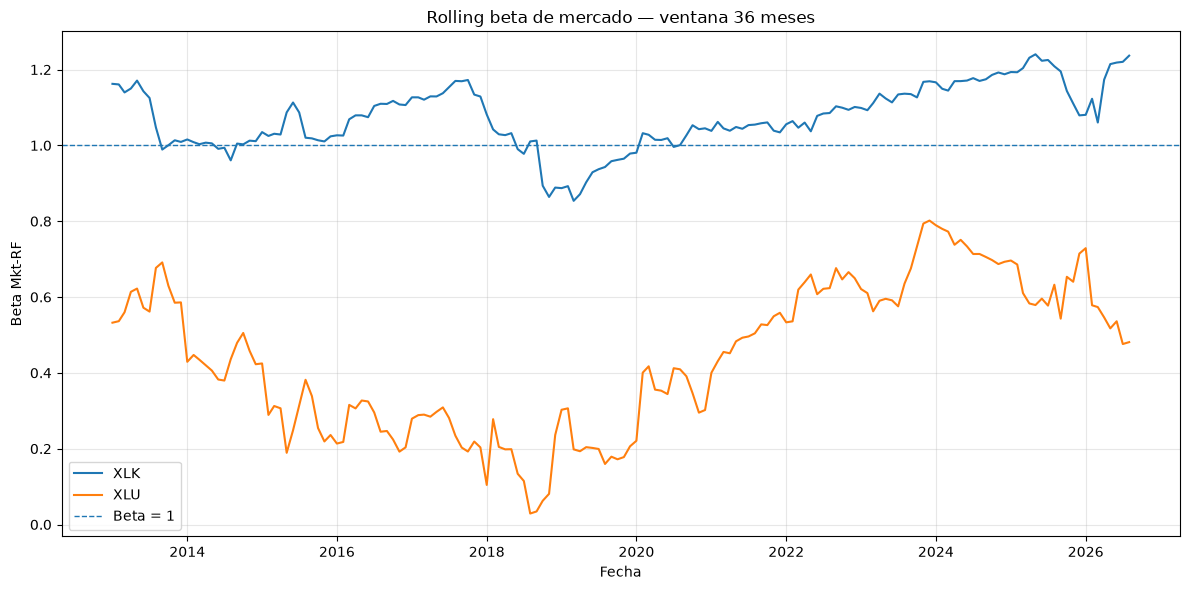

In [378]:
fig, ax = plt.subplots(
    figsize=(12, 6)
)

ax.plot(
    xlk_rolling.index,
    xlk_rolling["beta_Mkt-RF"],
    label="XLK",
)

ax.plot(
    xlu_rolling.index,
    xlu_rolling["beta_Mkt-RF"],
    label="XLU",
)

ax.axhline(
    1.0,
    linestyle="--",
    linewidth=1,
    label="Beta = 1",
)

ax.set_title(
    "Rolling beta de mercado — ventana 36 meses"
)

ax.set_ylabel(
    "Beta Mkt-RF"
)

ax.set_xlabel(
    "Fecha"
)

ax.legend()

ax.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

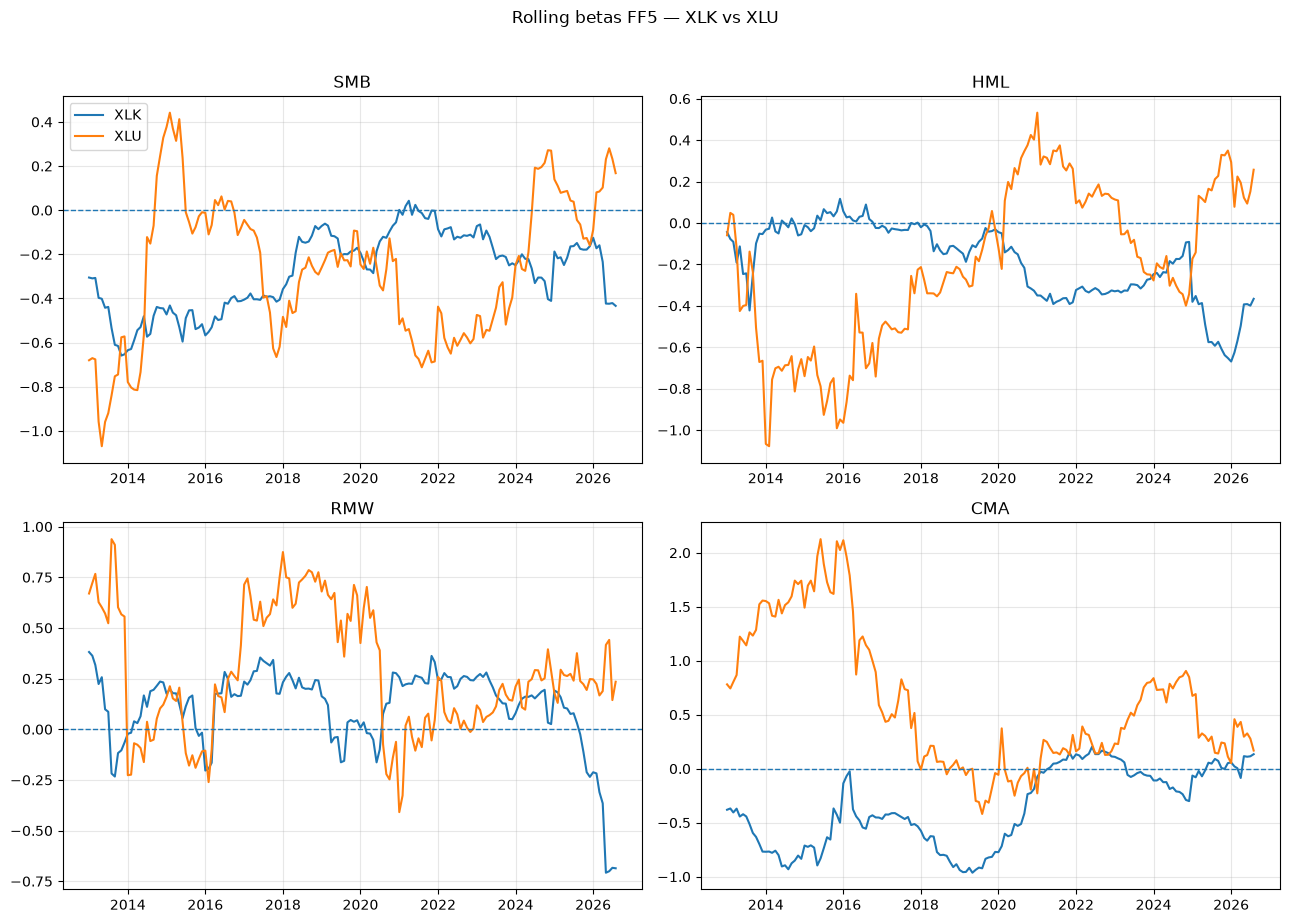

In [379]:
factor_columns = [
    "beta_SMB",
    "beta_HML",
    "beta_RMW",
    "beta_CMA",
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(13, 9),
)

axes = axes.flatten()

for ax, factor in zip(
    axes,
    factor_columns,
):
    ax.plot(
        xlk_rolling.index,
        xlk_rolling[factor],
        label="XLK",
    )

    ax.plot(
        xlu_rolling.index,
        xlu_rolling[factor],
        label="XLU",
    )

    ax.axhline(
        0,
        linewidth=1,
        linestyle="--",
    )

    ax.set_title(
        factor.replace(
            "beta_",
            "",
        )
    )

    ax.grid(
        alpha=0.3
    )

axes[0].legend()

plt.suptitle(
    "Rolling betas FF5 — XLK vs XLU",
    y=1.02,
)

plt.tight_layout()
plt.show()

In [380]:
latest_rolling_betas = pd.DataFrame(
    {
        "XLK": xlk_rolling.iloc[-1],
        "XLU": xlu_rolling.iloc[-1],
    }
)

latest_rolling_betas.round(3)

,XLK,XLU
beta_Mkt-RF,1.237,0.481
beta_SMB,-0.434,0.168
beta_HML,-0.366,0.257
beta_RMW,-0.686,0.235
beta_CMA,0.134,0.168


### Interpretación de los rolling betas

Las exposiciones factoriales no permanecen constantes a lo largo del tiempo.

La diferencia más estable entre ambos sectores aparece en el factor de mercado:

- `XLK` presenta un beta medio superior a uno y se comporta como un sector relativamente agresivo;
- `XLU` mantiene un beta medio claramente inferior a uno, coherente con su carácter defensivo.

También se observan diferencias relevantes en otros factores. En particular, la exposición media a `CMA` es negativa para `XLK` y positiva para `XLU`, lo que refleja perfiles económicos distintos frente al factor de inversión.

Las amplitudes entre mínimos y máximos muestran además que algunas exposiciones varían considerablemente según el periodo analizado.

Esto sugiere que interpretar los betas como parámetros estructuralmente constantes puede ser demasiado restrictivo. Una regresión estática resume bien la exposición media, pero puede ocultar cambios de régimen importantes.

## 10. Discusión final

Los resultados muestran que la optimización media-varianza puede producir carteras muy atractivas *in-sample*, pero también extremadamente sensibles a los parámetros estimados. La cartera Maximum Sharpe sin restricciones concentra aproximadamente el 80% del capital en `XLK` y `XLU`, mientras que imponer un máximo del 20% por activo reduce de forma notable esta concentración. De manera similar, una restricción de turnover del 20% limita el cambio respecto a Equal Weight y genera una solución menos extrema, a costa de sacrificar parte del Sharpe esperado.

La validación out-of-sample constituye la evidencia más importante sobre la robustez de la optimización. Con parámetros estimados entre 2010 y 2017, la cartera Maximum Sharpe presentaba un Sharpe esperado próximo a 1,55 y una volatilidad estimada inferior al 10%. Sin embargo, entre 2019 y 2026 su Sharpe realizado cae aproximadamente a 0,95 y la volatilidad aumenta hasta el 14,5%. Equal Weight obtiene un Sharpe ligeramente superior y SPY alcanza aproximadamente 1,06. Por tanto, la superioridad observada *in-sample* no persiste fuera de muestra.

Los modelos factoriales ayudan a entender parte de este resultado. En general, el paso desde CAPM hacia modelos multifactoriales aumenta el R² ajustado, mostrando que tamaño, value/growth, momentum, profitability e investment contienen información que el beta de mercado no captura. Por ejemplo, en `XLK` el R² ajustado aumenta aproximadamente de 0,76 bajo CAPM a 0,85 bajo FF5.

El alpha tampoco permanece constante al cambiar de modelo. En `XLK` pasa de aproximadamente 4,46% anual bajo CAPM a 3,66% bajo FF5. En la cartera Maximum Sharpe disminuye desde aproximadamente 4,25% bajo CAPM hasta 3,22% bajo FF5. Esto indica que parte del rendimiento inicialmente atribuido a alpha corresponde en realidad a exposiciones factoriales. Sin embargo, el alpha de Maximum Sharpe permanece positivo y su t-stat continúa ligeramente por encima de 2 bajo FF5.

Este resultado no debe interpretarse como evidencia concluyente de habilidad. La cartera fue seleccionada precisamente utilizando los datos históricos sobre los que se realizan estas regresiones, mientras que su comportamiento out-of-sample no supera a SPY. Por ello, parte del aparente alpha puede proceder de selección *in-sample* y error de estimación.

Finalmente, los rolling betas de 36 meses muestran que las exposiciones factoriales tampoco son constantes. `XLK` mantiene generalmente una exposición de mercado superior a `XLU`, pero los coeficientes de ambos sectores cambian considerablemente a lo largo del tiempo. En conjunto, los resultados favorecen el uso de restricciones, validación out-of-sample y análisis multifactorial frente a una interpretación mecánica del óptimo de Markowitz.

## 11. Conclusiones

Esta práctica muestra que la optimización media-varianza es una herramienta útil para estructurar carteras, pero sus resultados dependen de forma crítica de la calidad de las estimaciones de rentabilidad esperada y covarianza.

La cartera Maximum Sharpe obtiene el mejor resultado *in-sample*, pero concentra gran parte del capital en pocos sectores. La introducción de restricciones de peso máximo y turnover reduce esta concentración y genera soluciones más diversificadas y operativamente realistas, aunque con un menor Sharpe esperado.

La validación out-of-sample revela la principal limitación del enfoque. La cartera estimada entre 2010 y 2017 no mantiene su ventaja durante 2019–2026. Su volatilidad realizada es muy superior a la estimada y su Sharpe queda por debajo de SPY. Esto confirma que un óptimo histórico no garantiza persistencia futura.

El análisis CAPM muestra una relación positiva entre beta y retorno medio, aunque con desviaciones importantes entre sectores. Los modelos multifactoriales mejoran generalmente la capacidad explicativa respecto al CAPM y muestran que parte del rendimiento atribuido inicialmente a alpha está relacionado con exposiciones sistemáticas a factores.

La cartera Maximum Sharpe conserva un alpha positivo bajo FF5, pero este resultado es in-sample y debe contrastarse con su comportamiento out-of-sample, que no proporciona evidencia suficiente de habilidad persistente.

Finalmente, los rolling betas muestran que las exposiciones factoriales varían a lo largo del tiempo. Por tanto, tanto los parámetros de Markowitz como los betas factoriales deben interpretarse como estimaciones dinámicas y no como características permanentes de los activos.

En conjunto, los resultados apoyan una metodología de construcción de carteras basada no solo en optimización, sino también en restricciones realistas, diversificación, validación fuera de muestra y análisis multifactorial.

In [381]:
print("Práctica 2 ejecutada correctamente.")
print(
    "Muestra común 10 sectores:",
    sector_returns_common.index.min(),
    "->",
    sector_returns_common.index.max(),
)
print(
    "Número de observaciones:",
    len(sector_returns_common),
)

Práctica 2 ejecutada correctamente.
Muestra común 10 sectores: 2015-11-01 00:00:00 -> 2026-10-01 00:00:00
Número de observaciones: 132
